# Intelligent Loan Approval & Credit Risk Prediction

**Problem statement:** Predict whether a loan application will be **approved or rejected** (`Loan_Status`) from financial, employment and demographic attributes, and explain which factors drive the decision.

**Dataset:** Loan Prediction Problem Dataset (Dream Housing Finance), Kaggle: `<paste the exact Kaggle URL you downloaded train.csv from>`. 614 applications, 12 features + target.

**Workflow:** inspect data → clean and engineer features → EDA → preprocessing pipeline → compare 4 models → evaluate → tune → save pipeline → business insights.

## 1. Setup
Import the libraries and the shared feature-engineering code from `src/features.py` (the notebook and the Streamlit app use the **same** function, so the model always receives identical features). A fixed seed (`42`) keeps results reproducible.

In [28]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from src.features import add_features, NUM_FEATURES, CAT_FEATURES, BIN_FEATURES

np.random.seed(42)
sns.set_style("whitegrid")

## 2. Load the data

In [29]:
df = pd.read_csv("../data/train.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 3. Data inspection
Check size, column types, summary statistics, missing values and the balance of the target before touching anything.

In [30]:
print(df.shape)
df.info()

(614, 13)
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [31]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [32]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [33]:
df["Loan_Status"].value_counts(normalize=True)

Loan_Status
Y    0.687296
N    0.312704
Name: proportion, dtype: float64

**What the inspection shows**
- **Size:** 614 applications and 13 columns (12 features + `Loan_Status`).
- **Missing values:** `Credit_History` (50), `Self_Employed` (32), `LoanAmount` (22), `Dependents` (15), `Loan_Amount_Term` (14), `Gender` (13), `Married` (3). Numeric gaps will be filled with the **median**, categorical gaps with the **most frequent value**, inside the pipeline (to avoid data leakage).
- **Target balance:** about **68.7% approved / 31.3% rejected**. A model that always says "approved" would already score about 69% accuracy, so accuracy alone is not enough; precision, recall, F1 and ROC-AUC are reported too.
- **Skew:** `ApplicantIncome` has a mean of about 5,403 but a median of about 3,812 (max 81,000). That gap means a long right tail, which is corrected with a log transform.
- **`Credit_History`** is stored as 1.0/0.0 but is really a yes/no flag (credit guidelines met or not), so it is treated as a binary category and not scaled.

## 4. Cleaning and feature engineering
- Dropped `Loan_ID` (identifier, no predictive value) **before** checking duplicates. **0 duplicate rows** were found.
- Encoded the target: `Y → 1` (approved), `N → 0` (rejected).
- Created new features (`add_features` in `src/features.py`):
  - `Total_Income` = applicant + coapplicant income
  - `EMI` = loan amount × 1000 ÷ loan term (monthly principal repayment; `LoanAmount` is in thousands)
  - `Income_to_Loan` = `Total_Income` ÷ `LoanAmount`
  - `EMI_to_Income` = `EMI` ÷ `Total_Income`, a **repayment-burden ratio**. It is a proxy for debt-to-income, not a true DTI, because the dataset has no existing-debt or interest information.
  - `log1p` transform of the three income/loan columns and `Total_Income` to reduce skew.
- Missing values are **not** filled here; the pipeline does it later using training data only.

In [34]:
df = df.drop(columns="Loan_ID")
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})
df = add_features(df)
df.head()

Duplicates: 0


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income,EMI,Income_to_Loan,EMI_to_Income,ApplicantIncome_log,CoapplicantIncome_log,LoanAmount_log,Total_Income_log
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,1,5849.0,NaN,NaN,NaN,8.674197,0.000000,NaN,8.674197
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0,6091.0,355.555556,47.585938,0.058374,8.430327,7.319202,4.859812,8.714732
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1,3000.0,183.333333,45.454545,0.061111,8.006701,0.000000,4.204693,8.006701
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1,4941.0,333.333333,41.175000,0.067463,7.857094,7.765993,4.795791,8.505525
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1,6000.0,391.666667,42.553191,0.065278,8.699681,0.000000,4.955827,8.699681


## 5. Exploratory data analysis
### 5.1 Class balance

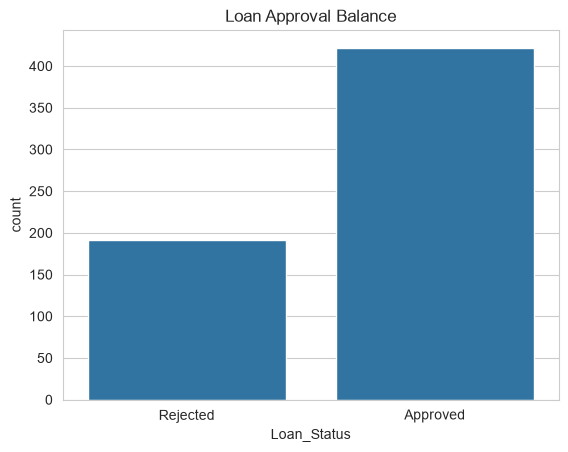

In [35]:
sns.countplot(x="Loan_Status", data=df)
plt.xticks([0, 1], ["Rejected", "Approved"])
plt.title("Loan Approval Balance")
plt.show()

**Insight:** 422 approved vs 192 rejected. The classes are moderately imbalanced (about 69/31), so the train/test split is stratified and models are judged on more than accuracy.

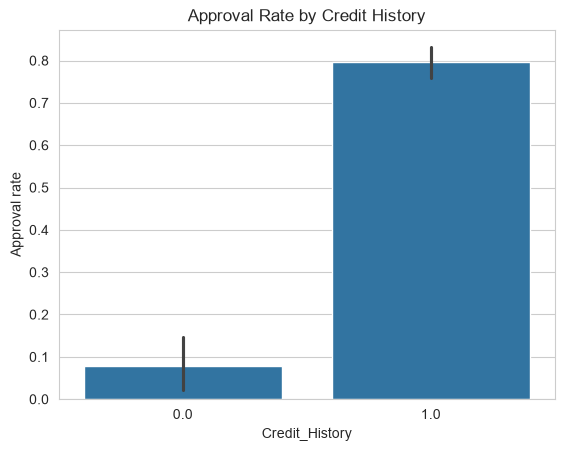

In [36]:
sns.barplot(x="Credit_History", y="Loan_Status", data=df)
plt.ylabel("Approval rate")
plt.title("Approval Rate by Credit History")
plt.show()

### 5.2 Credit history vs approval
**Insight:** This is the strongest pattern in the data. Applicants whose credit history meets guidelines are approved **79.6%** of the time, versus only **7.9%** for those who do not. Credit history is close to a gatekeeper for approval.

### 5.3 Approval rate by category

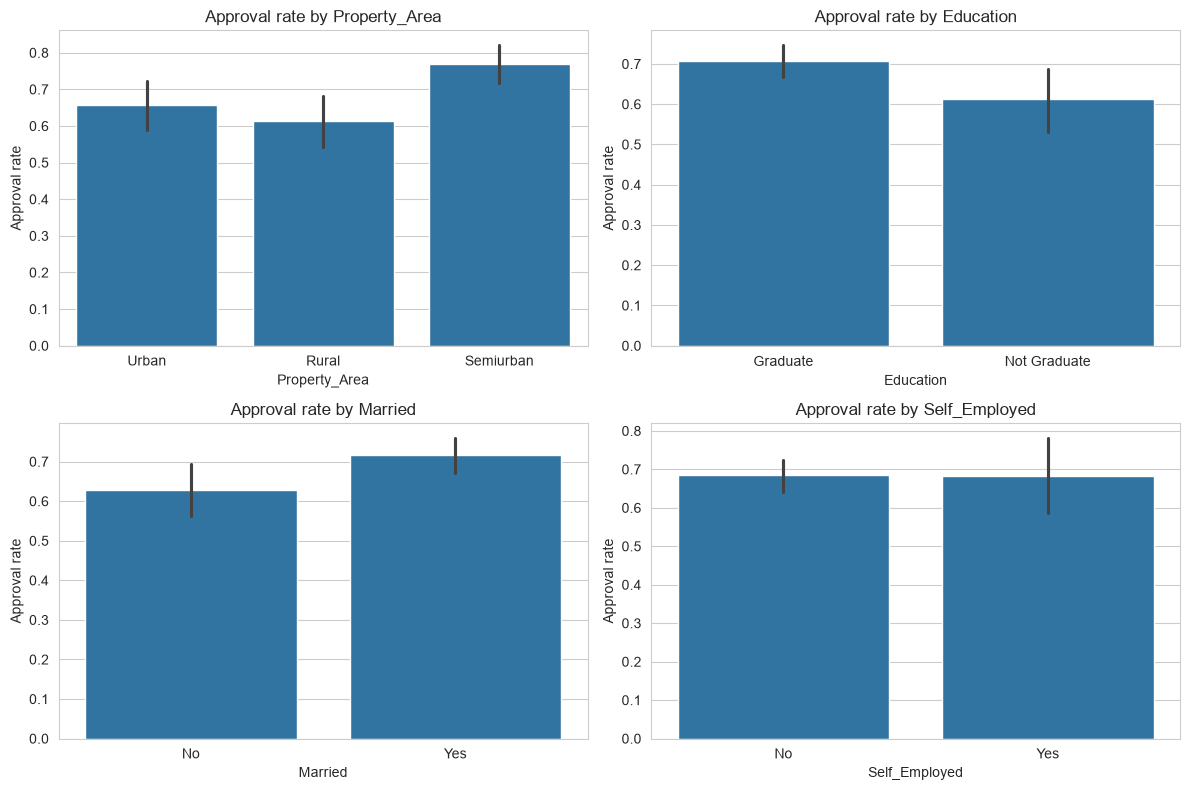

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Property_Area", "Education", "Married", "Self_Employed"]):
    sns.barplot(x=col, y="Loan_Status", data=df, ax=ax)
    ax.set_ylabel("Approval rate")
    ax.set_title(f"Approval rate by {col}")
plt.tight_layout()
plt.show()

**Insight:**
- **Property area:** Semiurban has the highest approval rate (**76.8%**), followed by Urban (**65.8%**) and Rural (**61.5%**).
- **Education:** Graduates are approved more often (**70.8%** vs **61.2%**).
- **Married:** Married applicants are approved more often (**71.6%** vs **62.9%**), possibly because of a second income.
- **Self-employed:** No difference (**68.3%** vs **68.6%**), so employment type alone does not drive approval.
These effects are real but much smaller than credit history.

### 5.4 Skewed numeric features: before and after the log transform

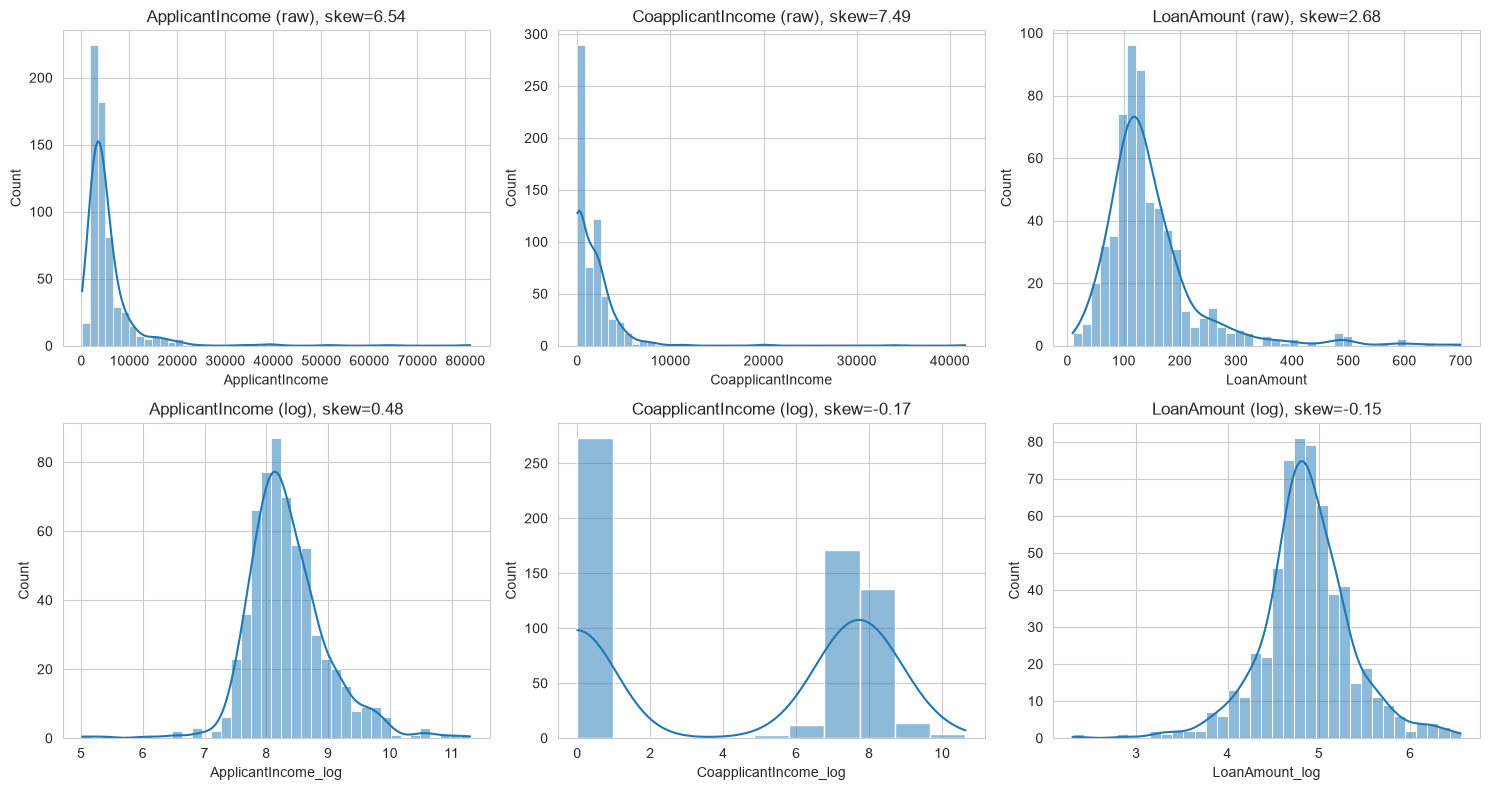

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    sns.histplot(df[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} (raw), skew={df[col].skew():.2f}")
    sns.histplot(df[col + "_log"], kde=True, ax=axes[1, i])
    axes[1, i].set_title(f"{col} (log), skew={df[col + '_log'].skew():.2f}")
plt.tight_layout()
plt.show()

**Insight:** The raw income and loan columns are strongly right-skewed (skewness: applicant income **6.5**, coapplicant income **7.5**, loan amount **2.7**). After `log1p` they are close to symmetric (**0.5, -0.2, -0.2**). The spike at zero in coapplicant income remains because many applicants have no coapplicant; that is expected.

### 5.5 Income and loan size: approved vs rejected

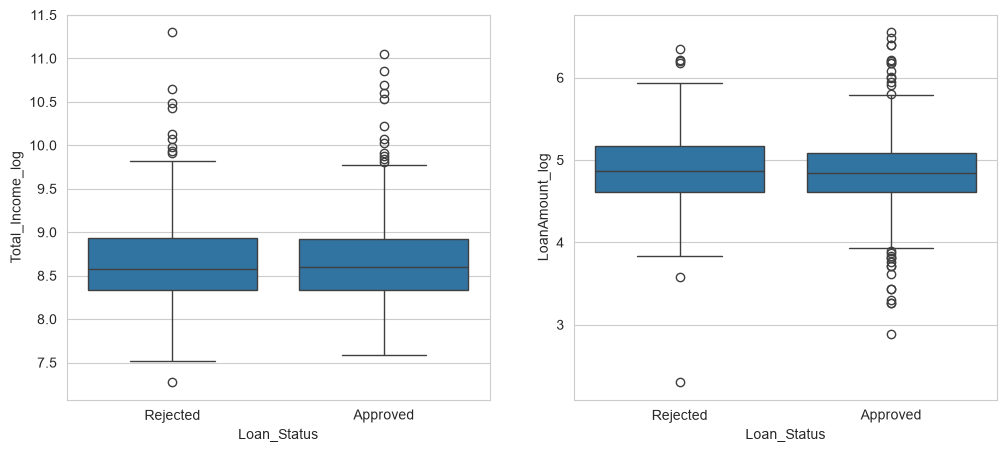

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ["Total_Income_log", "LoanAmount_log"]):
    sns.boxplot(x="Loan_Status", y=col, data=df, ax=ax)
    ax.set_xticklabels(["Rejected", "Approved"])
plt.show()

**Insight:** The distributions for approved and rejected applicants almost overlap. Median total income is about **5,290** for rejected vs **5,439** for approved, and the median loan is **129k** vs **126k**. Income and loan size alone do **not** separate the two groups; they matter only in combination with other factors.

### 5.6 Correlation with approval

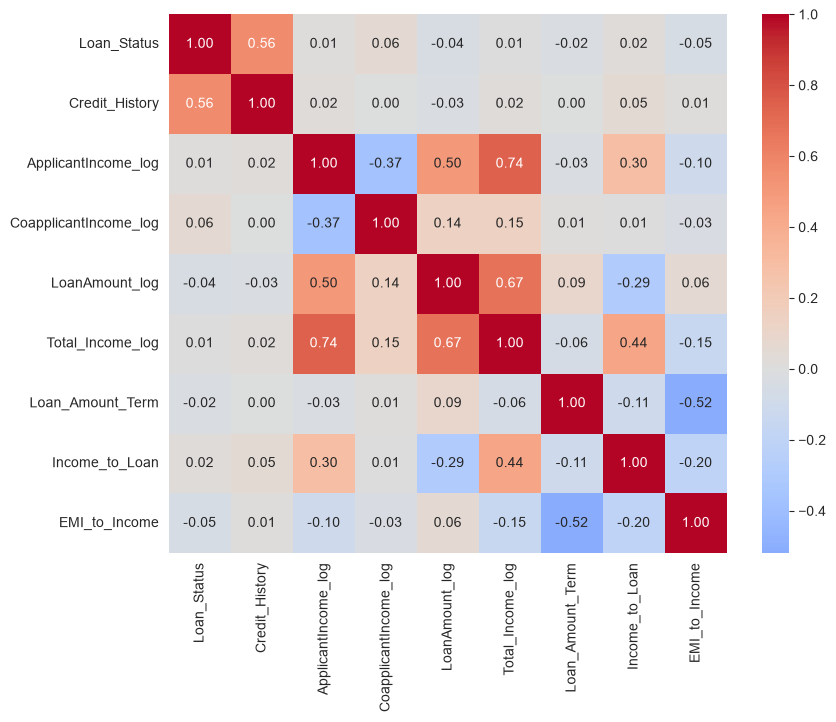

In [40]:
corr_cols = ["Loan_Status", "Credit_History"] + NUM_FEATURES
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Insight:** `Credit_History` has a correlation of about **0.56** with approval, while every numeric feature is within **±0.06**. The income-based features are also correlated with each other by construction (they are all built from the same income and loan columns).

## 6. Train/test split and preprocessing pipeline
**Split:** 80% train (491 rows) / 20% test (123 rows), **stratified** on the target so both parts keep the ~69/31 split, with `random_state=42`.

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df[NUM_FEATURES + CAT_FEATURES + BIN_FEATURES]
y = df["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(491, 14) (123, 14)


**Preprocessing (inside a scikit-learn `Pipeline`):**
| Column group | Steps |
|---|---|
| Numeric | median imputation → `StandardScaler` |
| Categorical | most-frequent imputation → `OneHotEncoder(handle_unknown="ignore")` |
| `Credit_History` (binary) | most-frequent imputation only (scaling a 0/1 flag adds nothing) |

Everything is **fit on the training data only**, which prevents data leakage. The same fitted pipeline is saved and reused by the Streamlit app.

In [42]:
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
bin_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])

preprocessor = ColumnTransformer([
    ("num", num_pipe, NUM_FEATURES),
    ("cat", cat_pipe, CAT_FEATURES),
    ("bin", bin_pipe, BIN_FEATURES),
])

## 7. Model training and comparison
Four models share the same preprocessing so the comparison is fair: Logistic Regression, Decision Tree (depth 4), Random Forest (200 trees) and Gradient Boosting. Each is scored on the test set (accuracy, precision, recall, F1, ROC-AUC) and with **5-fold stratified cross-validation** (CV ROC-AUC) on the training set.

In [43]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results, fitted = [], {}

for name, model in models.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "CV ROC-AUC": cv_auc,
    })
    fitted[name] = pipe

results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False).round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC
Model,,,,,,
Logistic Regression,0.854,0.832,0.988,0.903,0.878,0.723
Random Forest,0.870,0.888,0.929,0.908,0.874,0.773
Gradient Boosting,0.854,0.860,0.941,0.899,0.833,0.730
Decision Tree,0.846,0.844,0.953,0.895,0.747,0.653


**Results**
- All four models land within about **2.5 points of accuracy** (84.6%–87.0%), which suggests the data carries limited signal beyond credit history.
- Sorted by test ROC-AUC, **Logistic Regression** is first (0.878), but the test set has only 123 rows, where one applicant moves accuracy by about 0.8 points. The more reliable **cross-validated AUC favours Random Forest** (0.773 vs 0.723 for Logistic Regression).
- **Decision:** Random Forest is taken forward for tuning and as the final model because it is the most stable across folds. Logistic Regression's confusion matrix is still shown below as the top model on test AUC.

## 8. Evaluation of the top-ranked model (Logistic Regression)
Confusion matrix and classification report on the test set.

Best model: Logistic Regression


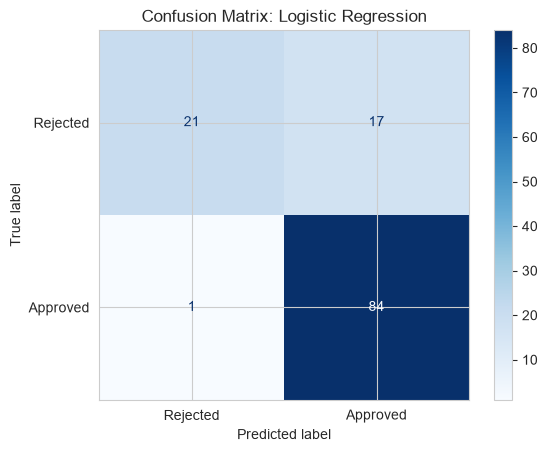

              precision    recall  f1-score   support

    Rejected       0.95      0.55      0.70        38
    Approved       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



In [44]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_name = results_df.index[0]
best_pipe = fitted[best_name]
print("Best model:", best_name)

ConfusionMatrixDisplay.from_estimator(
    best_pipe, X_test, y_test,
    display_labels=["Rejected", "Approved"], cmap="Blues"
)
plt.title(f"Confusion Matrix: {best_name}")
plt.show()

print(classification_report(y_test, best_pipe.predict(X_test),
                            target_names=["Rejected", "Approved"]))

**Reading the result:** Accuracy is **85%**. Logistic Regression approves almost every good applicant (recall **0.99**) but lets many risky ones through: only **21 of 38** rejected applicants are correctly rejected (recall **0.55**); **17 are wrongly approved**.

For a lender, a wrongly approved loan (possible default) usually costs more than a wrongly rejected one, so this weakness in the "Rejected" class matters more than the headline accuracy.

## 9. Key factors influencing approval (Logistic Regression)

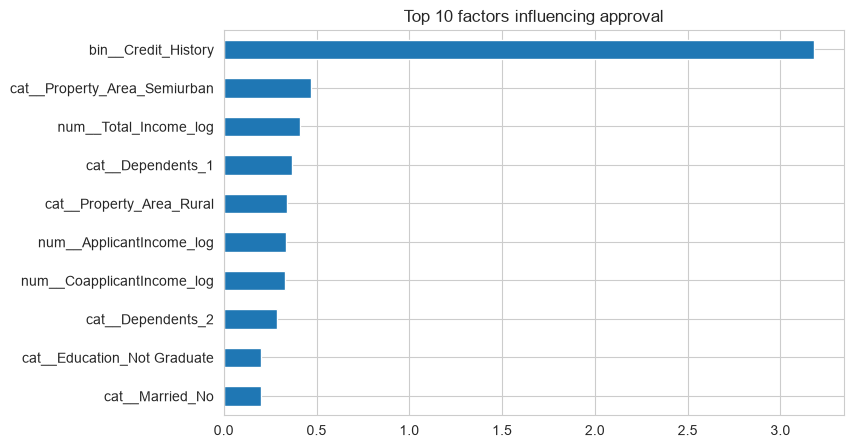

In [45]:
names = best_pipe.named_steps["prep"].get_feature_names_out()
model = best_pipe.named_steps["model"]

if hasattr(model, "feature_importances_"):
    vals = model.feature_importances_
else:
    vals = np.abs(model.coef_[0])

imp = pd.Series(vals, index=names).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", figsize=(8, 5), title="Top 10 factors influencing approval")
plt.show()

**Insight:** `Credit_History` dominates with a coefficient of about **3.2**; the next largest factor (Semiurban property, about **0.5**) is several times weaker. Income and loan features contribute only modestly.

## 10. Hyperparameter tuning (Random Forest)
`GridSearchCV` over 72 combinations (number of trees, max depth, min samples per leaf, class weight) × 5 folds, optimising ROC-AUC on the training data only.

In [46]:
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", RandomForestClassifier(random_state=42))])

param_grid = {
    "model__n_estimators": [100, 200, 400],
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 3, 5],
    "model__class_weight": [None, "balanced"],
}

grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
print(grid.best_params_)
print("Best CV AUC:", round(grid.best_score_, 3))

tuned = grid.best_estimator_
proba = tuned.predict_proba(X_test)[:, 1]
print("Test AUC:", round(roc_auc_score(y_test, proba), 3),
      "| Test F1:", round(f1_score(y_test, tuned.predict(X_test)), 3))

{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV AUC: 0.78
Test AUC: 0.88 | Test F1: 0.913


**Result:** The best combination is the scikit-learn default (100 trees, no depth limit, `min_samples_leaf=1`, no class weighting). Cross-validated AUC is **0.78** (vs 0.773 before tuning) and test AUC is **0.88** with F1 **0.913**. Tuning gave only a small gain, which suggests the model is limited by the information in the data rather than by its settings. The tuned model is the final model.

### Final model evaluation: tuned Random Forest
The confusion matrix and feature importance above are for Logistic Regression. The cells below show the same views for the **final (tuned Random Forest) model**.

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    tuned, X_test, y_test, display_labels=["Rejected", "Approved"], cmap="Blues"
)
plt.title("Confusion Matrix: Tuned Random Forest")
plt.show()
print(classification_report(y_test, tuned.predict(X_test),
                            target_names=["Rejected", "Approved"]))

names = tuned.named_steps["prep"].get_feature_names_out()
imp = pd.Series(tuned.named_steps["model"].feature_importances_, index=names).sort_values().tail(10)
imp.plot(kind="barh", figsize=(8, 5), title="Top 10 factors: Tuned Random Forest")
plt.show()

**Result:** The tuned Random Forest reaches **88% accuracy** (AUC 0.88, F1 0.913). Compared with Logistic Regression it catches far more risky applicants: **29 of 38** rejected applicants are correctly rejected (recall **0.76** vs 0.55), at the cost of rejecting 6 good applicants instead of 1. It still wrongly approves 9 risky applicants.

**Feature importance:** `Credit_History` is the top feature (importance about **0.20**, twice any other). Tree models spread importance across several continuous features (income, loan amount and the ratios, each about 0.10), because continuous columns offer many split points; treat those as supporting signals rather than primary drivers, in line with the near-identical medians in section 5.5.

## 11. Save the final pipeline
The complete tuned pipeline (imputation, scaling, encoding and model) is saved to `models/loan_pipeline.joblib` and reloaded as a check. The Streamlit app (`app.py`) loads this same file.

In [47]:
import joblib

final_pipe = tuned  # or best_pipe, whichever you chose
joblib.dump(final_pipe, "../models/loan_pipeline.joblib")

reloaded = joblib.load("../models/loan_pipeline.joblib")
print(reloaded.predict_proba(X_test.iloc[:3]))

[[0.94 0.06]
 [0.25 0.75]
 [0.39 0.61]]


**Check:** The reloaded pipeline returns approval probabilities for three test applicants, so the saved file works on its own.

## 12. Key risk insights (in plain business language)

1. **Credit history is the deciding factor.** Applicants with a clean history are approved about 80% of the time; without one, about 8%. It is the top factor in both models and by far the strongest correlation with the outcome.
2. **Income and loan size alone do not decide approval.** Approved and rejected applicants have almost the same typical income and loan amount. Affordability ratios (income vs loan, repayment burden) add supporting information, not a clear cut-off.
3. **Location and household matter modestly.** Semiurban properties (77%), graduates (71%) and married applicants (72%) are approved more often. Self-employment makes no difference.
4. **The model is useful as a screening tool, with one clear risk.** The final model is correct about 88% of the time and spots about 76% of risky applicants, but it still approves roughly 1 in 4 of them. A lender could raise the approval threshold above 50% to trade some approvals for fewer risky loans.
5. **Practical recommendations.**
   - Verify credit history first; it drives most decisions.
   - Send borderline cases (predicted probability around 40–60%) to a human reviewer instead of auto-deciding.
   - `Gender`, `Married` and `Dependents` are in this dataset, but using personal characteristics like these in real lending raises fairness and regulatory concerns; a production system should review or exclude them.

**Limitations**
- Small dataset (614 applications) and a small test set (123), so metrics have noticeable uncertainty.
- `EMI_to_Income` is a repayment-burden proxy (principal only, no interest or existing debt), not a true debt-to-income ratio.
- Missing `Credit_History` (50 rows) was filled with the most common value (good history), which may slightly overstate approvals for those applicants.